# Gate 5E: matched-size evaluation and ranking robustness

Inference only using the same 15 frozen 1,000-step Gate 5D rankings. No training, score optimization, fine-tuning, differentiable masks, or leaderboard submission. Gate 5D's mixed decision remains unchanged. The sole primary endpoint compares hierarchy against baseline at capped T1 actual edges; exact matches are labeled subsets.

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT/'src/mattr_matched_size').exists():
    ROOT = ROOT.parent
OUT = ROOT/'results/mattr_matched_size/20261023_gate5e'
RUN_TOPOLOGY = False
RUN_PREPARE = False
RUN_INFERENCE = False
RUN_REPORT = False
RUN_AUDIT = False
def run_stage(stage):
    prefix = ['wsl','-d','Ubuntu','--'] if sys.platform == 'win32' else []
    subprocess.run(prefix+['bash','src/mattr_matched_size/run_wsl.sh','--stage',stage],cwd=ROOT,check=True)
for flag,stage in [(RUN_TOPOLOGY,'topology'),(RUN_PREPARE,'prepare'),(RUN_INFERENCE,'inference'),(RUN_REPORT,'report'),(RUN_AUDIT,'audit')]:
    if flag:
        run_stage(stage)
print('Expensive stages default off. Existing completed/partial inference attempts cannot be overwritten.')


Expensive stages default off. Existing completed/partial inference attempts cannot be overwritten.


## Official topology, pruning scope and size targets

MIB selects a nominal fraction then prunes; the CPR/CMD integral uses nominal coordinates. P(n) is recorded for every n from 1 through 1,624. Closure boundaries reproduce original P(n), while partial groups may prune. The appended tail is never claimed pruning-free. T1/T2 are calculated from Gate 5D counts, not estimated constants.

In [2]:
display(json.loads((OUT/'phaseA_complete.json').read_text()))
display(json.loads((OUT/'official_pruning_semantics.json').read_text()))
display(pd.read_csv(OUT/'closure_correctness.csv'))
display(pd.read_csv(OUT/'jump_summary.csv'))
display(pd.read_csv(OUT/'exact_primary_comparisons.csv'))


{'passed': True,
 'original_rankings': 15,
 'ensemble_rankings': 3,
 'valid_closure_rankings': 15,
 'monotonic': True,
 'nested': True,
 'Gate5D_counts_and_masks_reproduced': True,
 'prefix_range': [1, 1624],
 'T1': 116,
 'T2': 296,
 'targets': [60, 80, 100, 116, 140, 180, 240, 296, 400, 640],
 'graph_analysis_seconds': 200.767321474,
 'registered_pair_comparisons': 1530,
 'both_exact_pairs': 675,
 'primary_pairs': 30,
 'primary_both_exact': 13,
 'model_forwards': 0}

{'apply_topn': {'file': 'external/matryoshka-attribution/deps/MIB-circuit-track/EAP-IG/src/eap/graph.py',
  'first_line': 443,
  'last_line': 529,
  'sha256': 'e87d98418cd1bcd5be20d189fc46a826dd7cdb8ca28216e6a7e167167b954f53'},
 'prune': {'file': 'external/matryoshka-attribution/deps/MIB-circuit-track/EAP-IG/src/eap/graph.py',
  'first_line': 567,
  'last_line': 599,
  'sha256': 'e87d98418cd1bcd5be20d189fc46a826dd7cdb8ca28216e6a7e167167b954f53'},
 'evaluate_area_under_curve': {'file': 'external/matryoshka-attribution/deps/MIB-circuit-track/MIB_circuit_track/evaluation.py',
  'first_line': 12,
  'last_line': 140,
  'sha256': '66bf4e8cb2cde67b6dcc30b84e9eee70505f0f52b7e811c1d77c745e30577ef4'},
 'grid_counting': 'nominal selection fraction of len(graph.edges) before pruning; integrals use percentages, not weighted_edge_counts',
 'pruning': 'iteratively remove nodes lacking incoming or outgoing edges, then edges with absent parents/children, until both masks stabilize; input treated as hav

,ranking,passed,all_boundaries_checked,every_prefix_in_known_groups_checked,additional_tail_nesting_samples,group_boundary_scope_max_original_prefix,known_closure_scope_max,tail_pruning_free_claim
0,baseline_s42,True,1337,1601,50,1624,1601,False
1,baseline_s43,True,1388,1612,50,1624,1612,False
2,baseline_s44,True,1384,1612,50,1624,1612,False
3,hierarchy_s42,True,1354,1613,50,1624,1613,False
4,hierarchy_s43,True,1396,1614,50,1624,1614,False
5,hierarchy_s44,True,1384,1609,50,1624,1609,False
6,gamma_zero_s42,True,1340,1614,50,1624,1614,False
7,gamma_zero_s43,True,1387,1616,50,1624,1616,False
8,gamma_zero_s44,True,1385,1607,50,1624,1607,False
9,shuffled_s42,True,1378,1586,50,1624,1586,False


,ranking,max_jump,mean_jump,zero_jump_prefixes,multi_edge_jump_prefixes
0,baseline_ensemble,18,0.969828,298,113
1,baseline_s42,55,0.985837,287,100
2,baseline_s43,13,0.992611,236,114
3,baseline_s44,11,0.992611,240,117
4,edge_l2_s42,61,0.987685,286,100
5,edge_l2_s43,16,0.995074,237,113
6,edge_l2_s44,10,0.992611,242,117
7,gamma_zero_ensemble,12,0.981527,245,119
8,gamma_zero_s42,15,0.993842,284,119
9,gamma_zero_s43,17,0.995074,237,124


,target,ranking_a,ranking_b,actual_a,actual_b,count_difference,both_exact,primary_paired_comparison
0,60,baseline_s42,hierarchy_s42,59,58,1,False,True
1,60,baseline_s43,hierarchy_s43,60,59,1,False,True
2,60,baseline_s44,hierarchy_s44,60,56,4,False,True
3,80,baseline_s42,hierarchy_s42,80,75,5,False,True
4,80,baseline_s43,hierarchy_s43,77,80,-3,False,True
5,80,baseline_s44,hierarchy_s44,79,80,-1,False,True
6,100,baseline_s42,hierarchy_s42,100,100,0,True,True
7,100,baseline_s43,hierarchy_s43,100,100,0,True,True
8,100,baseline_s44,hierarchy_s44,98,91,7,False,True
9,116,baseline_s42,hierarchy_s42,116,116,0,True,True


## Frozen protocol and new official cohort

Seed 5543 selects 512 official validation prompts, proportionally across nine exact template labels, excluding previous small cohorts, all Gate 5D prompts, training, and clean/donor/cross-role duplicates. Gate 1 already evaluated the full validation set historically: this cohort is new to smaller campaigns, not an untouched or private test.

In [3]:
p = json.loads((OUT/'gate5e_protocol.json').read_text())
print('Protocol SHA-256:',(OUT/'gate5e_protocol.sha256').read_text().strip())
display(p['algorithms'])
display(p['bootstrap'])
display(p['criteria'])
display(json.loads((OUT/'cohort_audit.json').read_text()))
display(pd.read_csv(OUT/'official_template_labels.csv'))
display(pd.read_csv(OUT/'cohort_ids_and_hashes.csv').head())


Protocol SHA-256: bb6421a5e5481a172559d0634ab9e71a90b942192f046a824b818bb4ecc90b39


{'topology': 'official signed apply_topn, prune=True for every n1..1624; original score/tie convention unchanged',
 'cap': 'largest audited nominal n with A(n)<=T, including n0; exact-size evaluations are the both-exact labeled subset, never extra forwards',
 'interpolation': 'at T1/T2, linear accuracy interpolation between largest attainable<=T and smallest attainable>=T; flag gap>max(10,0.10*T); no claim of directly evaluated circuit',
 'closure': 'first appearance in officialP(n), n1..1624; ties by original official rank; unseen edges appended in original order; unique negative ordinal scores; verify all known-group prefixes and50 full-range nesting samples; no tail pruning-free claim; full-grid NOMINAL effects only, no matched-size closure evaluations',
 'ensemble': 'within each source vector, signed descending ordinal ranks tied by canonical edge index; equal average of3 ranks; final ties by canonical index; unique negative ordinal scores; no validation weights'}

{'resamples': 5000,
 'seed': 5643,
 'unit': 'shared prompts within exact template strata, fixedcounts; same resample all methods/seeds/targets; fixed trained seeds equally weighted, never3N independent rows',
 'primary': 'single T1 endpoint, two-sided95% percentile interval; success lower>0',
 'secondary': 'T2, controls, exact subsets and interpolation use descriptive unadjusted95% intervals',
 'R': 'pooled cap-difference / pooled nominal0.5%-difference; shared-draw percentile ratioCI; unstable if denominator95%intervalcontains0 or abs(point)<1/cohortN; report invalid draw count'}

{'primary': 'T1 cap mean>0, >=2of3 positive seeds, paired prompt95%lower>0, all correctness valid',
 'T2': 'secondary only; never changes T1decision',
 'classification': ['Non-replication if nominal lower<=0',
  'Ranking-quality effect if primary passes and stableR>=0.5',
  'Mostly connectivity if nominal lower>0, primary fails, and (capCIcontains0 or stableR<0.25)',
  'Mixed otherwise'],
 'interpretation': 'descriptive; R is advantage-retention ratio, never a causal proportion; capped success not exact-size superiority',
 'ensemble_diagnostic': 'baselineensemble cap accuracy>=.90 at T2; compare3components without assuming3-run training is cheap'}

{'selected': 512,
 'eligible_unique_rows': 9296,
 'selection_seed': 5543,
 'official_rows': 10000,
 'official_fingerprint': 'c93b9b8332b9b344',
 'selected_template_counts': {'0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4e1f74ea5092db50cea': 64,
  '1761850092a4b3fa58baabc01960df818ec1acd216fcdc2e6484b244669c9422': 64,
  '2a973fb4edec3c205233ae7e923a3cb5e1a1f226036229c4f36b686538ef1616': 64,
  '4f505e7ee3bfc724786cd2d5d1dbbc632492c0b67e00957ae36ffa81b7c4b970': 60,
  '6c714790566383068be623b67c91c9251d410916a811b1a47b2e83611bd953a5': 61,
  '77cfacab10ad6ef85cb004f33b7264c507c8004405a773295fad5049bb6af8e2': 60,
  'af843482ab88d863192825f98880df874c339b5ebf3d78676a26406bdd5cc246': 60,
  'd1df0b3439dc91aa88317c15aac11b38122bac7f3c3b3ed7fcb64c35ab5c2a30': 62,
  'f2c936c186d3219c4c69f340ad5942be8fecaf3f3ac9d73dad0bbb9a6401539c': 17},
 'exclusion_manifests': [{'path': 'results/mattr_optimization/20261021T034206Z/train_manifest.csv',
   'sha256': '91678d39222d914be92eff069751aa29afe036298ced0c5

,template_id,official_template
0,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...,Friends {name_A} and {name_B} found a {object}...
1,1761850092a4b3fa58baabc01960df818ec1acd216fcdc...,When {name_A} and {name_B} were done exploring...
2,2a973fb4edec3c205233ae7e923a3cb5e1a1f226036229...,"Then, {name_A} and {name_B} were thinking abou..."
3,4f505e7ee3bfc724786cd2d5d1dbbc632492c0b67e0095...,"Later, {name_A} and {name_B} met at the {place..."
4,6c714790566383068be623b67c91c9251d410916a811b1...,"After the lunch, {name_A} and {name_B} went to..."
5,77cfacab10ad6ef85cb004f33b7264c507c8004405a773...,While {name_A} and {name_B} relaxed at the {pl...
6,af843482ab88d863192825f98880df874c339b5ebf3d78...,Once {name_A} and {name_B} finished at the {pl...
7,d1df0b3439dc91aa88317c15aac11b38122bac7f3c3b3e...,"Afterwards, {name_A} and {name_B} went to the ..."
8,f2c936c186d3219c4c69f340ad5942be8fecaf3f3ac9d7...,"Then, {name_A} and {name_B} had a long argumen..."


,example,official_filtered_index,clean_sha256,corrupted_sha256,correct_token,incorrect_token,template_id
0,0,61,ac437064ae939fe4a39db06e98e6c559f2bb64f573297c...,dffd25b6d53392e73e7f7df172454c94aecabebd056308...,5274,5264,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...
1,1,211,210a941eb0fc910c37eca80b634c1c8e5fb41f6ee53326...,9ea048ab3945562ad077bff65ac4ad9275d494dc074472...,3759,5274,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...
2,2,259,0380fa68d3959197d16bace136597da3a1b834c336c4eb...,cc84f3b9481bfc89fd2c338fb4a7a3b1684727e47c7dcc...,5502,6502,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...
3,3,316,5132d37822e1cc5bc67016cdd8c1558f16246349506415...,86c319a48cdfef4788c9a4f86392d062985e8522b94dc1...,4502,3362,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...
4,4,431,fd68f2f8fb6ccb98029e94cd52e3df02269ad21154689c...,0f8e57b44ee19daaec075a82b74ae2022aecaefc04a41a...,5741,13514,0c50a0d0a0e0751325cc6addfa17c1ba0947006d8453b4...


## Original nominal versus capped-size circuits

At-most-T uses the largest nominal prefix with A(n)<=T; a shortfall remains possible. Exact comparisons require both circuits to attain the same T. No separate exact-size evaluation or matched-size closure evaluation is performed. Full-vocabulary top-1 is separate from the positive-margin IOI metric.

In [4]:
display(pd.read_csv(OUT/'official_metrics.csv'))
display(pd.read_csv(OUT/'matched_results.csv'))
display(pd.read_csv(OUT/'paired_cap_comparisons.csv'))
display(pd.read_csv(OUT/'exact_subset_primary_comparisons.csv'))
display(pd.read_csv(OUT/'interpolated_estimates.csv'))
display(pd.read_csv(OUT/'interpolated_paired_differences.csv'))


,ranking,kind,method,seed,CPR,CMD,accuracy_log_AUC
0,baseline_s42,original,baseline,42,9.832498,8.858491,0.640914
1,baseline_s43,original,baseline,43,10.145767,9.156906,0.763709
2,baseline_s44,original,baseline,44,10.042320,9.054458,0.744303
3,hierarchy_s42,original,hierarchy,42,9.958384,8.973859,0.752987
4,hierarchy_s43,original,hierarchy,43,9.981525,8.990909,0.788251
5,hierarchy_s44,original,hierarchy,44,9.948157,8.955348,0.824358
6,gamma_zero_s42,original,gamma_zero,42,9.909312,8.924800,0.745947
7,gamma_zero_s43,original,gamma_zero,43,10.021894,9.031407,0.786203
8,gamma_zero_s44,original,gamma_zero,44,9.946041,8.953232,0.824358
9,shuffled_s42,original,shuffled,42,9.807821,8.823066,0.723859


,ranking,method,seed,kind,selection,target,nominal_n,actual_edges,shortfall,exact,mask_sha256,accuracy,mean_margin,faithfulness,top1
0,baseline_s42,baseline,42,original,cap,60,131,59,1,False,644a7d96d7dba09c9154c7251d69764b0cb7d4a4a7e535...,0.041016,-2.628802,0.009117,0.015625
1,baseline_s42,baseline,42,original,cap,80,150,80,0,True,afcb70491c2371a8f4043b32bbd128a3f798f8a5ab9356...,0.041016,-2.629003,0.009083,0.015625
2,baseline_s42,baseline,42,original,cap,100,178,100,0,True,8f245d0efa92b8f4cd2cbc7f60f46336fc6269ae937fcf...,0.046875,-2.583278,0.016780,0.021484
3,baseline_s42,baseline,42,original,cap,116,189,116,0,True,a19d6c8fe71fa19dc508ddcf0d6ed5924e17850a3fbe91...,0.046875,-2.578999,0.017500,0.021484
4,baseline_s42,baseline,42,original,upper,116,189,116,0,True,a19d6c8fe71fa19dc508ddcf0d6ed5924e17850a3fbe91...,0.046875,-2.578999,0.017500,0.021484
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211,gamma_zero_ensemble,gamma_zero,ensemble,ensemble,cap,240,259,240,0,True,8d5a6e8420c18b22220f59ca81616ed9dc3ac812b1845c...,0.894531,4.684549,1.240204,0.808594
212,gamma_zero_ensemble,gamma_zero,ensemble,ensemble,cap,296,313,296,0,True,6d98f5f0a44474efb976c7d473f4dfd6290b822747c3e0...,0.986328,8.859446,1.942982,0.947266
213,gamma_zero_ensemble,gamma_zero,ensemble,ensemble,upper,296,313,296,0,True,6d98f5f0a44474efb976c7d473f4dfd6290b822747c3e0...,0.986328,8.859446,1.942982,0.947266
214,gamma_zero_ensemble,gamma_zero,ensemble,ensemble,cap,400,427,399,1,False,ccd4e562200ae07c928d62830641da31bb36f543288710...,0.996094,13.837500,2.780959,0.988281


,target,comparator,seed,mean,lower,upper,corrected_prompts,broken_prompts,positive_seeds
0,60,baseline,42,0.283203,0.246094,0.318359,145.0,0.0,NaN
1,60,baseline,43,0.166016,0.134766,0.197266,85.0,0.0,NaN
2,60,baseline,44,0.396484,0.355469,0.437500,203.0,0.0,NaN
3,60,baseline,equal_seed_mean,0.281901,0.253906,0.309896,NaN,NaN,3.0
4,60,gamma_zero,42,0.107422,0.082031,0.134766,55.0,0.0,NaN
...,...,...,...,...,...,...,...,...,...
155,640,shuffled,equal_seed_mean,0.000000,0.000000,0.000000,NaN,NaN,0.0
156,640,edge_l2,42,0.001953,0.000000,0.005859,1.0,0.0,NaN
157,640,edge_l2,43,0.000000,0.000000,0.000000,0.0,0.0,NaN
158,640,edge_l2,44,0.000000,0.000000,0.000000,0.0,0.0,NaN


,target,exact_seeds,n_fixed_seeds,mean,lower,upper,scope
0,60,[],0,NaN,NaN,NaN,no exact paired comparison attained by both or...
1,80,[],0,NaN,NaN,NaN,no exact paired comparison attained by both or...
2,100,"[42, 43]",2,0.291016,0.258789,0.322266,descriptive exact subset of already evaluated ...
3,116,[42],1,0.408203,0.367188,0.447266,descriptive exact subset of already evaluated ...
4,140,[43],1,0.113281,0.076172,0.152344,descriptive exact subset of already evaluated ...
5,180,[],0,NaN,NaN,NaN,no exact paired comparison attained by both or...
6,240,[43],1,0.001953,-0.007812,0.011719,descriptive exact subset of already evaluated ...
7,296,"[43, 44]",2,-0.003906,-0.009766,0.000977,descriptive exact subset of already evaluated ...
8,400,"[42, 43, 44]",3,0.018880,0.010417,0.027995,descriptive exact subset of already evaluated ...
9,640,"[42, 43, 44]",3,0.000000,0.000000,0.000000,descriptive exact subset of already evaluated ...


,ranking,method,seed,target,lower_actual,upper_actual,gap,upper_weight,interpolated_accuracy,directly_evaluated,large_gap_flag
0,baseline_s42,baseline,42,116,116,116,0,0.000000,0.046875,True,False
1,baseline_s42,baseline,42,296,296,296,0,0.000000,0.263672,True,False
2,baseline_s43,baseline,43,116,116,116,0,0.000000,0.357422,True,False
3,baseline_s43,baseline,43,296,296,296,0,0.000000,0.998047,True,False
4,baseline_s44,baseline,44,116,116,116,0,0.000000,0.189453,True,False
5,baseline_s44,baseline,44,296,296,296,0,0.000000,0.994141,True,False
6,hierarchy_s42,hierarchy,42,116,116,116,0,0.000000,0.455078,True,False
7,hierarchy_s42,hierarchy,42,296,295,297,2,0.500000,0.699219,False,False
8,hierarchy_s43,hierarchy,43,116,114,118,4,0.500000,0.442383,False,False
9,hierarchy_s43,hierarchy,43,296,296,296,0,0.000000,1.000000,True,False


,target,seed,mean,lower,upper,interpolated
0,116,42,0.408203,0.367188,0.447266,True
1,116,43,0.084961,0.050781,0.120117,True
2,116,44,0.555469,0.514453,0.597266,True
3,116,equal_seed_mean,0.349544,0.322980,0.375651,True
4,296,42,0.435547,0.394531,0.476562,True
5,296,43,0.001953,0.000000,0.005859,True
6,296,44,-0.009766,-0.019531,0.000000,True
7,296,equal_seed_mean,0.142578,0.127604,0.156266,True


## Primary uncertainty and advantage-retention ratio

Five thousand template-stratified shared prompt draws use seed 5643. Fixed trained seeds are equally weighted, never treated as 3N independent prompt observations. R = capped T1 gain / fresh nominal 0.5% gain is descriptive, not a causal proportion explained by pruning. Near-zero or zero-crossing denominators are flagged. T2 and controls are secondary and cannot change the primary rule.

In [5]:
display(json.loads((OUT/'gate5e_decision.json').read_text()))
display(json.loads((OUT/'research_summary.json').read_text()))


{'primary_success': True,
 'checks': {'positive_mean': True,
  'positive_at_least2_seeds': True,
  'paired_prompt_lower_positive': True,
  'correct_evaluator_and_masks': True},
 'cap_T1': {'mean': 0.3450520833333333,
  'lower': 0.318359375,
  'upper': 0.37174479166666663},
 'nominal_0.5pct': {'mean': 0.3684895833333333,
  'lower': 0.3411458333333333,
  'upper': 0.3958333333333333},
 'positive_cap_seeds': 3,
 'per_seed_cap_changes': [0.408203125, 0.0703125, 0.556640625],
 'per_seed_nominal_changes': [0.400390625, 0.150390625, 0.5546875],
 'advantage_retention_ratio': {'stable': True,
  'point': 0.9363957597173145,
  'lower': 0.9094201289674878,
  'upper': 0.9628318584070796,
  'denominator_nearzero_threshold': 0.001953125,
  'invalid_bootstrap_denominators': 0,
  'causal_explained_fraction': False},
 'classification': 'Ranking-quality effect',
 'scope': 'capped-size comparison; no causal fraction or training-seed significance claim',
 'new_training_authorized': False}

{'classification': 'Ranking-quality effect',
 'primary_success': True,
 'T1': 116,
 'T2': 296,
 'primary': {'primary_success': True,
  'checks': {'positive_mean': True,
   'positive_at_least2_seeds': True,
   'paired_prompt_lower_positive': True,
   'correct_evaluator_and_masks': True},
  'cap_T1': {'mean': 0.3450520833333333,
   'lower': 0.318359375,
   'upper': 0.37174479166666663},
  'nominal_0.5pct': {'mean': 0.3684895833333333,
   'lower': 0.3411458333333333,
   'upper': 0.3958333333333333},
  'positive_cap_seeds': 3,
  'per_seed_cap_changes': [0.408203125, 0.0703125, 0.556640625],
  'per_seed_nominal_changes': [0.400390625, 0.150390625, 0.5546875],
  'advantage_retention_ratio': {'stable': True,
   'point': 0.9363957597173145,
   'lower': 0.9094201289674878,
   'upper': 0.9628318584070796,
   'denominator_nearzero_threshold': 0.001953125,
   'invalid_bootstrap_denominators': 0,
   'causal_explained_fraction': False},
  'classification': 'Ranking-quality effect',
  'scope': 'cappe

## Closure and equal-weight seed ensembles

Closure differences on the official nominal grid can reflect different actual sizes; every comparison records both actual counts. All three ensembles average signed ordinal ranks equally, with canonical-index ties. Their three-run training cost is reported separately from inference-only construction, without claiming cheaper discovery.

In [6]:
display(pd.read_csv(OUT/'closure_nominal_effects.csv'))
display(pd.read_csv(OUT/'closure_rank_stability.csv'))
display(pd.read_csv(OUT/'closure_cross_seed_stability.csv'))
display(pd.read_csv(OUT/'ensemble_vs_components.csv'))
display(pd.read_csv(OUT/'ensemble_training_cost.csv'))
display(pd.read_csv(OUT/'ensemble_construction_cost.csv'))


,original,closure,fraction,original_actual,closure_actual,original_accuracy,closure_accuracy,accuracy_delta,CPR_delta,CMD_delta,same_mask,interpretation
0,baseline_s42,baseline_s42_closure,0.001,2,4,0.039062,0.039062,0.000000,0.006839,-0.001066,False,nominal-grid size/counting effect; not matched...
1,baseline_s42,baseline_s42_closure,0.002,2,64,0.039062,0.041016,0.001953,0.006839,-0.001066,False,nominal-grid size/counting effect; not matched...
2,baseline_s42,baseline_s42_closure,0.005,92,158,0.041016,0.060547,0.019531,0.006839,-0.001066,False,nominal-grid size/counting effect; not matched...
3,baseline_s42,baseline_s42_closure,0.010,273,324,0.148438,0.607422,0.458984,0.006839,-0.001066,False,nominal-grid size/counting effect; not matched...
4,baseline_s42,baseline_s42_closure,0.020,638,649,1.000000,1.000000,0.000000,0.006839,-0.001066,False,nominal-grid size/counting effect; not matched...
...,...,...,...,...,...,...,...,...,...,...,...,...
145,edge_l2_s44,edge_l2_s44_closure,0.050,1612,1612,1.000000,1.000000,0.000000,0.006682,0.004099,True,nominal-grid size/counting effect; not matched...
146,edge_l2_s44,edge_l2_s44_closure,0.100,3247,3247,1.000000,1.000000,0.000000,0.006682,0.004099,True,nominal-grid size/counting effect; not matched...
147,edge_l2_s44,edge_l2_s44_closure,0.200,6498,6498,1.000000,1.000000,0.000000,0.006682,0.004099,True,nominal-grid size/counting effect; not matched...
148,edge_l2_s44,edge_l2_s44_closure,0.500,16245,16245,1.000000,1.000000,0.000000,0.006682,0.004099,True,nominal-grid size/counting effect; not matched...


,ranking,closure,signed_rank_spearman,ordering_scope
0,baseline_s42,baseline_s42_closure,0.999998,first-appearance groups from original prefixes...
1,baseline_s43,baseline_s43_closure,0.999999,first-appearance groups from original prefixes...
2,baseline_s44,baseline_s44_closure,0.999999,first-appearance groups from original prefixes...
3,hierarchy_s42,hierarchy_s42_closure,0.999998,first-appearance groups from original prefixes...
4,hierarchy_s43,hierarchy_s43_closure,0.999998,first-appearance groups from original prefixes...
5,hierarchy_s44,hierarchy_s44_closure,0.999998,first-appearance groups from original prefixes...
6,gamma_zero_s42,gamma_zero_s42_closure,0.999998,first-appearance groups from original prefixes...
7,gamma_zero_s43,gamma_zero_s43_closure,0.999999,first-appearance groups from original prefixes...
8,gamma_zero_s44,gamma_zero_s44_closure,0.999998,first-appearance groups from original prefixes...
9,shuffled_s42,shuffled_s42_closure,0.999997,first-appearance groups from original prefixes...


,method,kind,seed_a,seed_b,fraction,rank_spearman,pruned_edge_jaccard
0,baseline,original,42,43,0.005,0.387018,0.153846
1,baseline,original,42,43,0.010,0.387018,0.426471
2,baseline,original,42,43,0.020,0.387018,0.511848
3,baseline,original,42,43,0.050,0.387018,0.467794
4,baseline,original,42,44,0.005,0.411244,0.238095
...,...,...,...,...,...,...,...
115,edge_l2,closure,42,44,0.050,0.414261,0.482711
116,edge_l2,closure,43,44,0.005,0.435441,0.463636
117,edge_l2,closure,43,44,0.010,0.435441,0.541766
118,edge_l2,closure,43,44,0.020,0.435441,0.511059


,method,target,actual_edges,ensemble_accuracy,seed42_accuracy,seed43_accuracy,seed44_accuracy,component_min,component_mean,ensemble_minus_component_min,baseline_T2_90pct_pass
0,baseline,60,59,0.068359,0.041016,0.087891,0.126953,0.041016,0.085286,0.027344,False
1,baseline,80,80,0.068359,0.041016,0.121094,0.156250,0.041016,0.106120,0.027344,False
2,baseline,100,100,0.068359,0.046875,0.181641,0.189453,0.046875,0.139323,0.021484,False
3,baseline,116,116,0.136719,0.046875,0.357422,0.189453,0.046875,0.197917,0.089844,False
4,baseline,140,140,0.138672,0.046875,0.457031,0.259766,0.046875,0.254557,0.091797,False
5,baseline,180,180,0.591797,0.070312,0.748047,0.771484,0.070312,0.529948,0.521484,False
6,baseline,240,240,0.921875,0.072266,0.990234,0.982422,0.072266,0.681641,0.849609,False
7,baseline,296,296,0.939453,0.263672,0.998047,0.994141,0.263672,0.751953,0.675781,True
8,baseline,400,398,0.980469,0.906250,1.000000,0.996094,0.906250,0.967448,0.074219,False
9,baseline,640,640,0.998047,1.000000,1.000000,1.000000,1.000000,1.000000,-0.001953,False


,method,separate_training_runs,optimizer_updates_total,existing_training_seconds,existing_adaptation_seconds,scope
0,baseline,3,3000,826.607682,857.891130,reused three1000-step runs; not newGate5E comp...
1,hierarchy,3,3000,833.839568,868.271972,reused three1000-step runs; not newGate5E comp...
2,gamma_zero,3,3000,826.626805,859.440512,reused three1000-step runs; not newGate5E comp...


,method,CPU_construction_seconds_replay,reproduced_export,model_forwards,scope
0,baseline,0.009558,True,0,timed deterministic replay; original construct...
1,hierarchy,0.009298,True,0,timed deterministic replay; original construct...
2,gamma_zero,0.009749,True,0,timed deterministic replay; original construct...


## Compute and preservation checks

The first-ranking workload projection is a mandatory stop gate at two hours. CUDA-synchronized timers count real forwards and individual example-forwards. Exact caches store immutable outputs, never patched activations. Allocated/reserved memory is not total physical VRAM occupancy. No model gradients or weight updates are produced.

In [7]:
for name in ['first_ranking_projection.json','correctness_passed.json','exact_cache_correctness.json','model_weight_audit.json','inference_process_summary.json','final_validation.json']:
    display(json.loads((OUT/name).read_text()))
display(pd.read_csv(OUT/'per_ranking_nominal_compute.csv'))
display(pd.read_csv(OUT/'per_ranking_matched_compute.csv'))


{'first_ranking_seconds': 95.69785421900002,
 'requested_circuits': 546,
 'projected_seconds': 5225.102840357401,
 'threshold_seconds': 7200,
 'includes_first_reference_overhead': True,
 'passed': True}

{'passed': True,
 'official_patcher_unchanged': True,
 'batch_repeat_singleton': True,
 'reference_cache_equivalent': True,
 'full_returns_clean': True,
 'nested_masks': True,
 'mask_audit_points': 10,
 'optimizer_updates': 0,
 'backward_calls': 0}

{'passed': True,
 'official_uncached_equals_cached': True,
 'per_prompt_margin_and_top1_equal': True,
 'repeat_forwards': 0,
 'cache_hits': 11,
 'masked_activations_cached': False,
 'scope': 'same2 frozen examples, unchanged official patcher and integrals'}

{'passed': True,
 'before_sha256': '2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5f63d46fc45e6469a76',
 'after_sha256': '2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5f63d46fc45e6469a76',
 'stored_model_gradients': False,
 'backward_calls': 0,
 'optimizer_updates': 0}

{'success': True,
 'projection_stop': False,
 'seconds': 3486.62767838,
 'counts': {'forward_batches': 19956,
  'example_forwards': 391332,
  'backward_calls': 0,
  'optimizer_updates': 0},
 'unique_prompts': 512,
 'output_cache_hits': 166,
 'unique_exact_masks': 381,
 'reference_scalar_hits': 64,
 'mutable_activation_cache': False}

{'passed': True,
 'protocol_sha256': 'bb6421a5e5481a172559d0634ab9e71a90b942192f046a824b818bb4ecc90b39',
 'historical_files_unchanged': 7834,
 'full_grid_rankings': 33,
 'capped_upper_queries': 216,
 'cohort_prompts': 512,
 'clean_donor_crossrole_overlap': 0,
 'no_matched_closure_queries': True,
 'original_checkpoint_hashes_verified': True,
 'model_weights_unchanged': True,
 'actual_forwards_verified': True,
 'optimizer_updates': 0,
 'model_backwards': 0,
 'Gate5D_decision_unchanged': True,
 'additional_model_forwards': 0,
 'seconds': 107.861834222}

,stage,success,seconds,forward_batches,example_forwards,backward_calls,optimizer_updates,peak_allocated_mib,peak_reserved_mib,sampled_peak_cpu_rss_mib
0,nominal_baseline_s42,True,95.697854,572,11264,0,0,2452.533203,6056.0,1700.781250
1,nominal_baseline_s43,True,72.163990,416,8192,0,0,2452.533203,6056.0,1701.578125
2,nominal_baseline_s44,True,80.037641,468,9216,0,0,2452.533203,6056.0,1701.968750
3,nominal_hierarchy_s42,True,72.311517,416,8192,0,0,2452.533203,6056.0,1702.078125
4,nominal_hierarchy_s43,True,72.011383,416,8192,0,0,2452.533203,6056.0,1699.746094
5,nominal_hierarchy_s44,True,80.440252,468,9216,0,0,2452.533203,6056.0,1699.777344
6,nominal_gamma_zero_s42,True,72.373905,416,8192,0,0,2452.533203,6056.0,1699.792969
7,nominal_gamma_zero_s43,True,73.636052,416,8192,0,0,2452.533203,6056.0,1699.968750
8,nominal_gamma_zero_s44,True,64.304240,364,7168,0,0,2452.533203,6056.0,1699.976562
9,nominal_shuffled_s42,True,79.939780,468,9216,0,0,2452.533203,6056.0,1700.113281


,stage,success,seconds,forward_batches,example_forwards,backward_calls,optimizer_updates,peak_allocated_mib,peak_reserved_mib,sampled_peak_cpu_rss_mib
0,matched_baseline_s42,True,90.876781,520,10240,0,0,2452.533203,6056.0,1701.621094
1,matched_baseline_s43,True,83.570106,468,9216,0,0,2452.533203,6056.0,1701.687500
2,matched_baseline_s44,True,73.174258,416,8192,0,0,2452.533203,6056.0,1701.703125
3,matched_hierarchy_s42,True,91.318959,520,10240,0,0,2452.533203,6056.0,1701.820312
4,matched_hierarchy_s43,True,101.884747,572,11264,0,0,2452.533203,6056.0,1701.832031
5,matched_hierarchy_s44,True,90.691025,520,10240,0,0,2452.533203,6056.0,1701.843750
6,matched_gamma_zero_s42,True,99.641481,572,11264,0,0,2452.533203,6056.0,1701.855469
7,matched_gamma_zero_s43,True,98.012128,572,11264,0,0,2452.533203,6056.0,1701.976562
8,matched_gamma_zero_s44,True,72.476051,416,8192,0,0,2452.533203,6056.0,1701.992188
9,matched_shuffled_s42,True,99.828264,572,11264,0,0,2452.533203,6056.0,1702.449219


## Executed figures and report

All conclusions derive from completed results and frozen criteria. Stop after Gate 5E. No further training, refinement beyond the registered deterministic rankings, next gate, or leaderboard action is authorized.

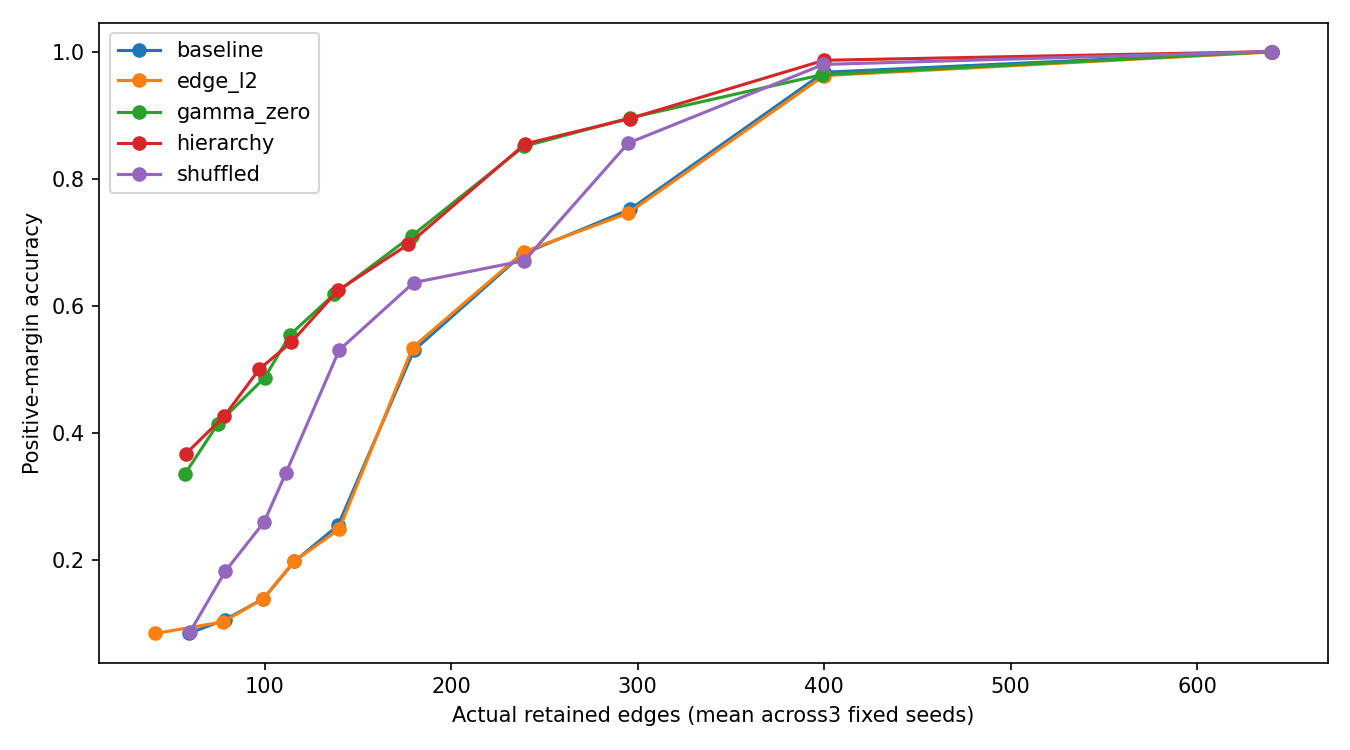

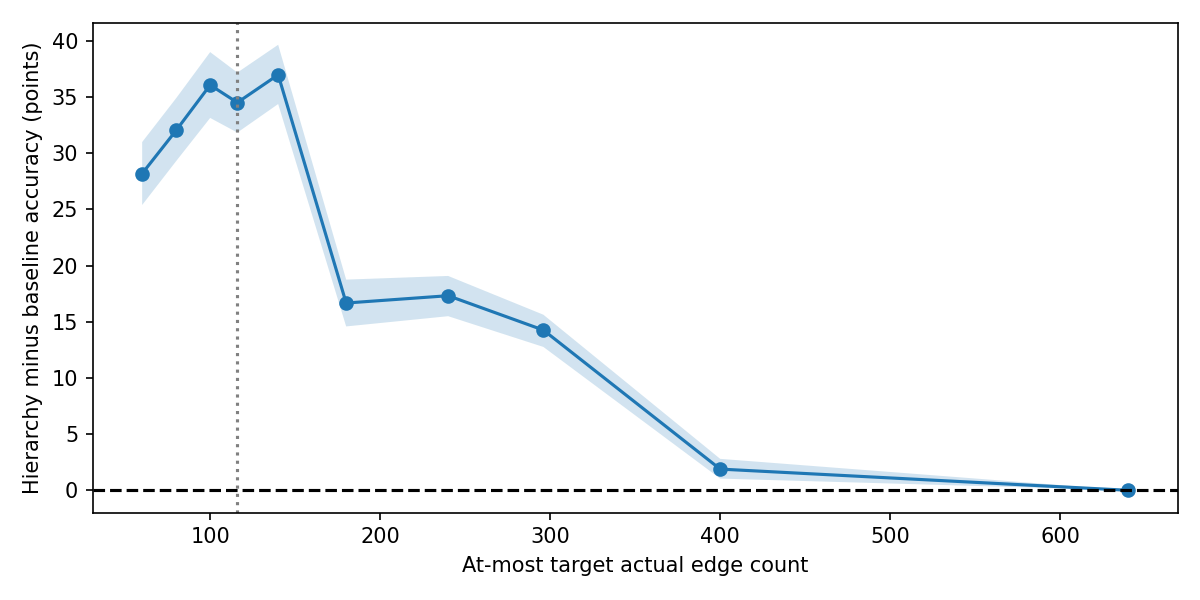

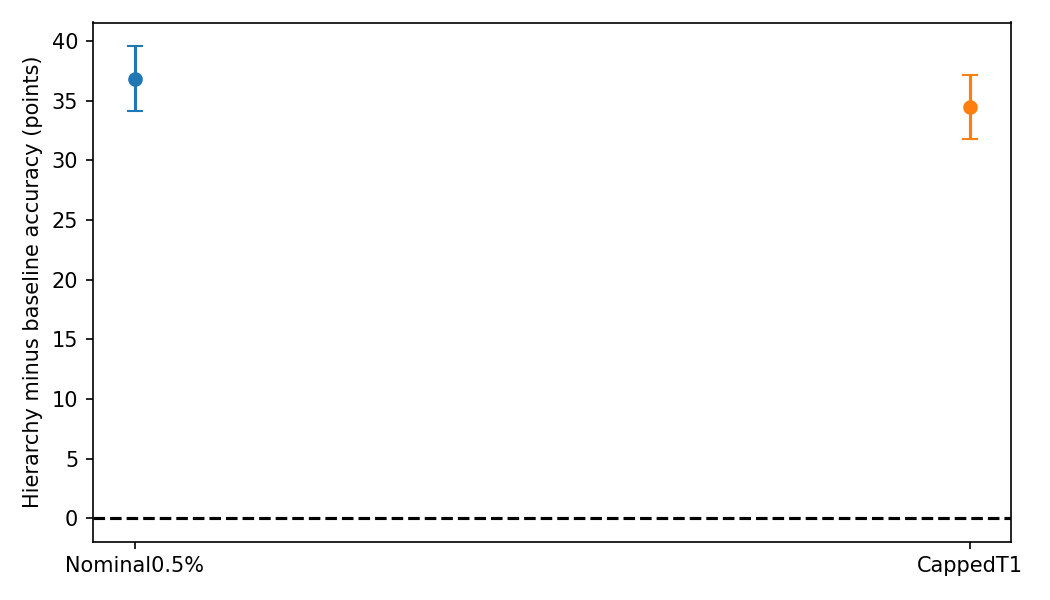

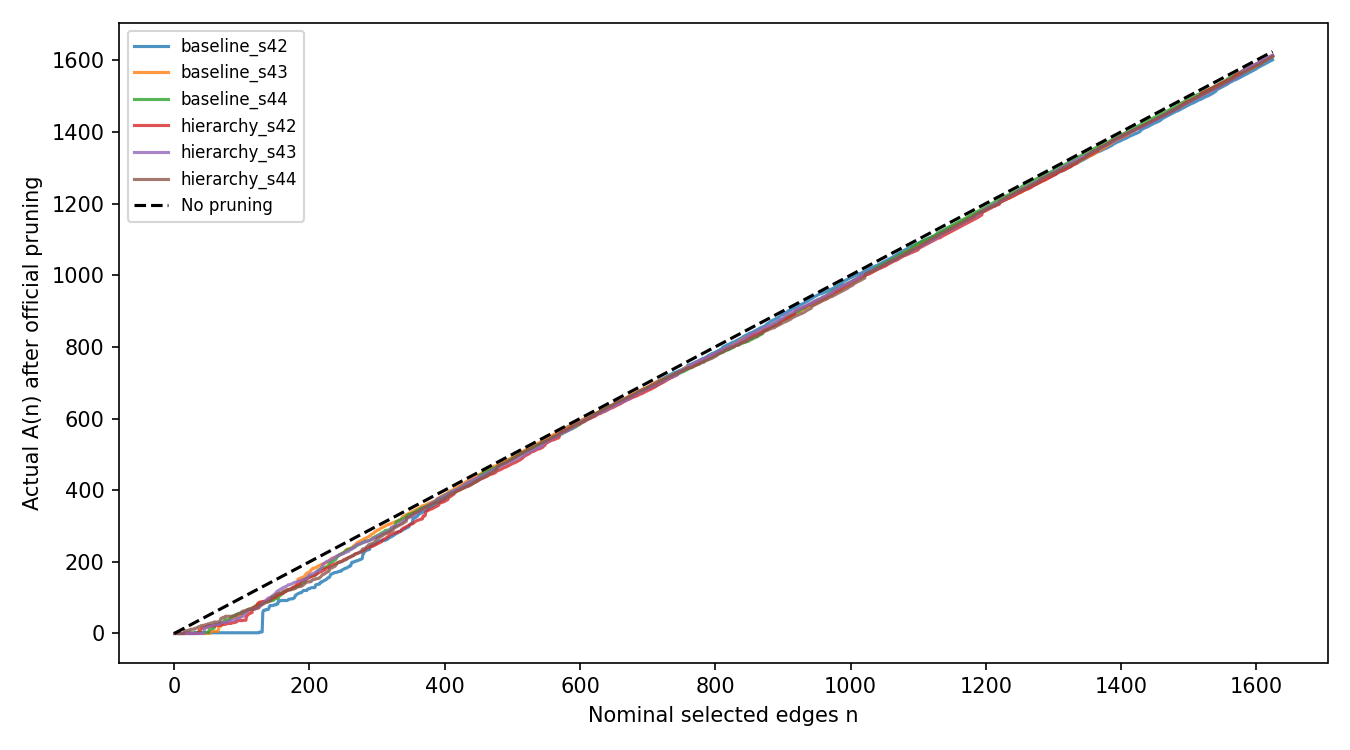

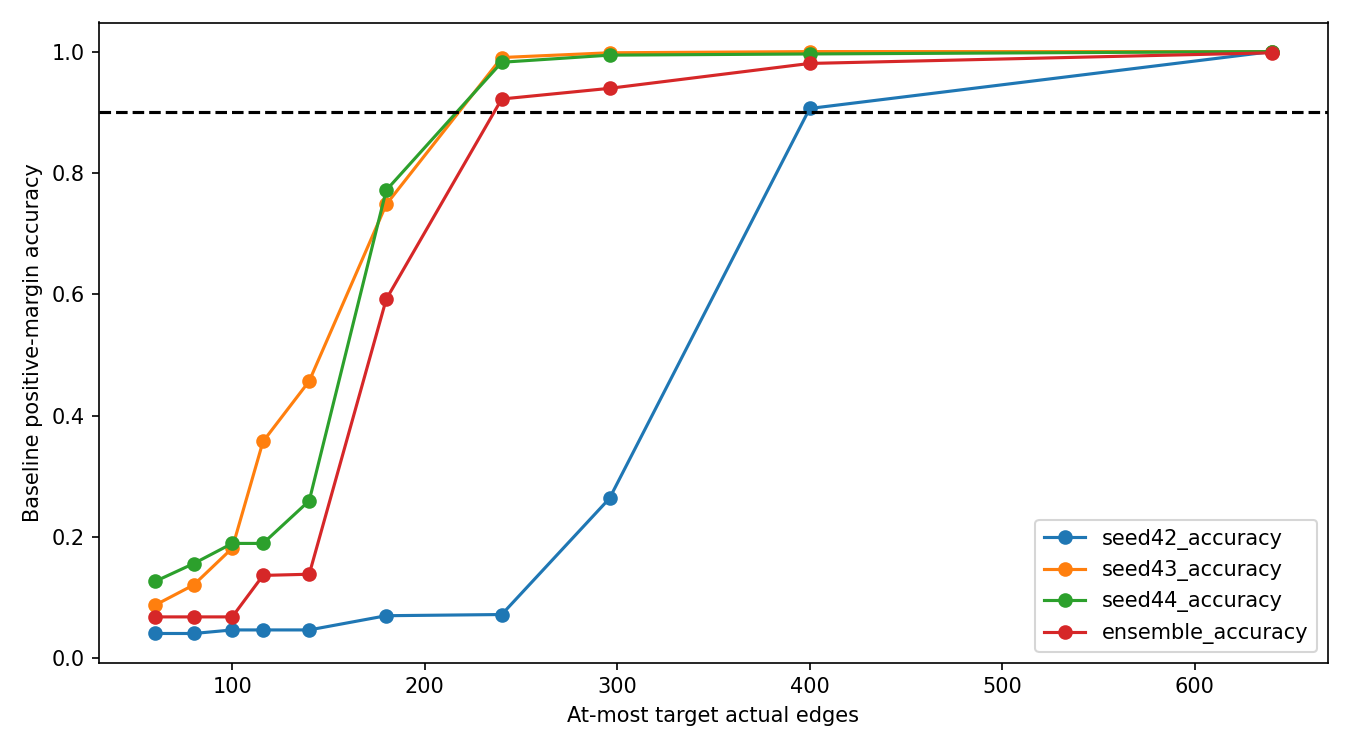

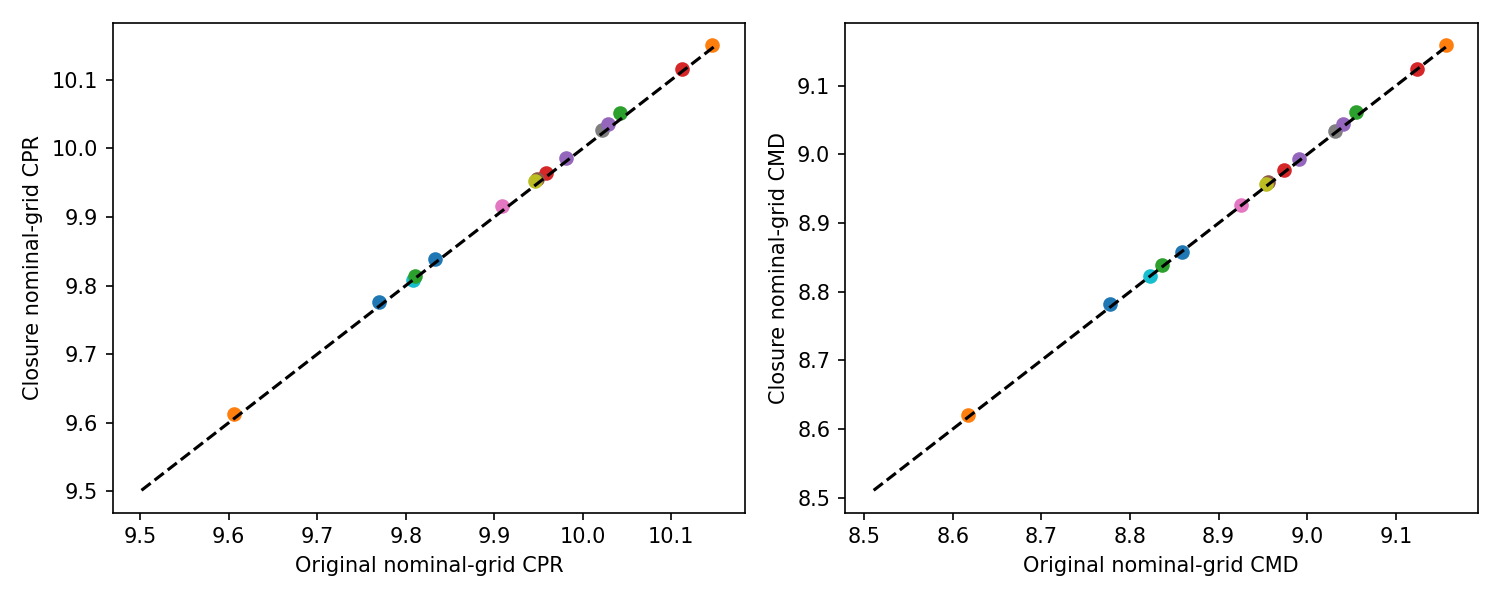

# Gate 5E: Matched-size circuit evaluation and ranking robustness

## Outcome interpretation

Frozen classification: **Ranking-quality effect**. Primary capped-T1 success: **True**. Official pruning passed monotonicity and nestedness for every audited prefix. The fresh nominal 0.5% gain was **36.85 percentage points** (paired 95% interval 34.11 to 39.58). At capped **T1=116**, hierarchy averaged **54.30%** accuracy versus **19.79%**, a **34.51-point** difference (95% interval 31.84 to 37.17); seed changes 42/43/44 were **+40.82, +7.03, +55.66 points**. **3/3** seeds improved. These are positive-margin IOI accuracies, separate from vocabulary top-1.

The **advantage-retention ratio R is 93.64% (paired 95% interval 90.94% to 96.28%)**. It is not a causal proportion explained by pruning. The registered primary comparison is capped: seed 42 compares 116 against 116 actual edges; seeds 43/44 compare 114/113 hierarchy edges against 116 baseline edges. Only seed 42 is exact at T1. Across all 10 targets and 3 paired seeds, **13/30** comparisons are exact. The exact subsets and their prompt intervals are reported below; capped success does not establish three-seed exact-size superiority.

At secondary **T2=296**, the pooled hierarchy-minus-baseline difference was **14.26 points** (descriptive 95% interval 12.76 to 15.63). Actual sizes at T2 are 296/295 for baseline/hierarchy seed 42, and 296/296 for seeds 43/44. This pooled gain is driven by seed 42; the exactly matched seeds 43/44 average a small -0.39-point difference (interval includes zero). At 400 actual edges the exactly matched mean gain is +1.89 points; at 640 it is zero. Dense curves therefore show a compact benefit that fades as accuracy saturates. These secondary endpoints do not change the primary decision.

Control mean positive-margin accuracy:

| method | 116 | 296 |
| --- | --- | --- |
| baseline | 0.1979 | 0.7520 |
| edge_l2 | 0.1979 | 0.7461 |
| gamma_zero | 0.5547 | 0.8958 |
| hierarchy | 0.5430 | 0.8945 |
| shuffled | 0.3366 | 0.8561 |

Secondary paired contrasts (hierarchy minus comparator, accuracy fractions):

| comparator | target | mean | lower | upper | positive_seeds |
| --- | --- | --- | --- | --- | --- |
| baseline | 116 | 0.3451 | 0.3184 | 0.3717 | 3.0000 |
| gamma_zero | 116 | -0.0117 | -0.0208 | -0.0026 | 0.0000 |
| shuffled | 116 | 0.2064 | 0.1849 | 0.2285 | 2.0000 |
| edge_l2 | 116 | 0.3451 | 0.3184 | 0.3717 | 3.0000 |
| baseline | 296 | 0.1426 | 0.1276 | 0.1563 | 2.0000 |
| gamma_zero | 296 | -0.0013 | -0.0059 | 0.0033 | 0.0000 |
| shuffled | 296 | 0.0384 | 0.0221 | 0.0540 | 3.0000 |
| edge_l2 | 296 | 0.1484 | 0.1335 | 0.1634 | 2.0000 |

A gamma-zero tie or advantage means the residual penalty is not established as the cause of the compact gain. Real grouping beat shuffled grouping by 20.64 points at T1 and 3.84 points at T2 on these capped comparisons; the secondary prompt intervals above exclude zero. These findings favor a structural parameter-sharing explanation over residual regularization alone, conditional on the fixed rankings and cohort. They do not establish training-seed significance. No group-stability correlation alone establishes causal fidelity.

The baseline ensemble reached **93.95%** accuracy at capped T2 (actual **296** edges); the prespecified 90% diagnostic **passed**. Its component seed 42/43/44 accuracies there were **26.37%/99.80%/99.41%**. This reduces the poor seed-42 outcome but does not beat the strongest seed. All ensemble comparisons and their three-run training costs remain separate from marginal construction/inference costs.

Closure mean changes in official CPR/CMD:

| method | CPR_delta | CMD_delta |
| --- | --- | --- |
| baseline | 0.0072 | 0.0028 |
| edge_l2 | 0.0049 | 0.0024 |
| gamma_zero | 0.0063 | 0.0029 |
| hierarchy | 0.0059 | 0.0036 |
| shuffled | 0.0045 | 0.0028 |

MIB integrates the nominal fraction coordinates, so closure changes are **nominal-grid counting effects**, with actual sizes listed in closure_nominal_effects.csv. They are not matched-size ranking-quality evidence. No matched-size closure evaluations were run. Closure audit covers all known first-appearance boundaries from original prefixes <= 1624; appended-tail nesting samples do not establish a pruning-free tail. Diagnostic rank correlations use canonical ordinal tie breaks; original ranking evaluation retains the pinned official Torch sort.

Original nominal mean CPR was **10.006862 baseline versus 9.962688 hierarchy**; CMD was **9.023285 versus 8.973372**. Thus the compact accuracy benefit did not improve leaderboard CPR. CPR, CMD, compact decision recovery and full-model fidelity remain distinct. Gate 5D's mixed decision is preserved.

Measured inference-process wall time: **58.11 minutes**, evaluation-stage wall time **57.61 minutes**, CPU topology/construction **200.77 seconds**. There were **19,956** real root forwards and **391,332** example-forwards, with **166** exact-output cache hits. CUDA peaks: **2.40 GiB allocated**, **5.91 GiB reserved**; these are not physical GPU occupancy or kernel-utilization timers. Zero optimizer updates or backward calls were executed.

Registered-target skip lists for all 18 original/ensemble rankings:

| ranking | exact_registered_targets | skipped_registered_targets | exact_count | registered_targets |
| --- | --- | --- | --- | --- |
| baseline_s42 | [80, 100, 116, 180, 296, 400, 640] | [60, 140, 240] | 7 | 10 |
| baseline_s43 | [60, 100, 116, 140, 180, 240, 296, 400, 640] | [80] | 9 | 10 |
| baseline_s44 | [60, 116, 140, 180, 240, 296, 400, 640] | [80, 100] | 8 | 10 |
| hierarchy_s42 | [100, 116, 240, 400, 640] | [60, 80, 140, 180, 296] | 5 | 10 |
| hierarchy_s43 | [80, 100, 140, 240, 296, 400, 640] | [60, 116, 180] | 7 | 10 |
| hierarchy_s44 | [80, 296, 400, 640] | [60, 100, 116, 140, 180, 240] | 4 | 10 |
| gamma_zero_s42 | [100, 180, 240, 296, 640] | [60, 80, 116, 140, 400] | 5 | 10 |
| gamma_zero_s43 | [60, 100, 180, 296, 400] | [80, 116, 140, 240, 640] | 5 | 10 |
| gamma_zero_s44 | [100, 296, 400, 640] | [60, 80, 116, 140, 180, 240] | 4 | 10 |
| shuffled_s42 | [60, 80, 100, 140, 180, 240, 296, 400, 640] | [116] | 9 | 10 |
| shuffled_s43 | [60, 100, 140, 180, 240, 296, 640] | [80, 116, 400] | 7 | 10 |
| shuffled_s44 | [60, 140, 180, 400, 640] | [80, 100, 116, 240, 296] | 5 | 10 |
| edge_l2_s42 | [80, 100, 116, 140, 180, 296, 400, 640] | [60, 240] | 8 | 10 |
| edge_l2_s43 | [60, 100, 116, 140, 240, 296, 400, 640] | [80, 180] | 8 | 10 |
| edge_l2_s44 | [60, 80, 140, 180, 240, 400, 640] | [100, 116, 296] | 7 | 10 |
| baseline_ensemble | [80, 100, 116, 140, 180, 240, 296, 640] | [60, 400] | 8 | 10 |
| hierarchy_ensemble | [80, 100, 116, 140, 296, 400] | [60, 180, 240, 640] | 6 | 10 |
| gamma_zero_ensemble | [100, 116, 180, 240, 296, 640] | [60, 80, 140, 400] | 6 | 10 |

Recommendation: prioritize a future independent evaluation of the existing gamma-zero component parameterization and rank ensembles for compact circuits, while retaining standard MAttr as the CPR reference. The penalty has not demonstrated value here. Treat closure as a separate nominal-counting direction and charge ensembles for three trained runs. This is a recommendation only. Stop after Gate 5E; no further gate, training, new mask/refinement algorithm, or leaderboard submission has run.

## Actual frozen decision

**Ranking-quality effect**. Primary capped-T1 success: **True**. T1=**116**, T2=**296**, computed as medians over all15 saved Gate5D actual counts, not hardcoded estimates. Full decision and advantage-retention ratio:

```json
{
  "primary_success": true,
  "checks": {
    "positive_mean": true,
    "positive_at_least2_seeds": true,
    "paired_prompt_lower_positive": true,
    "correct_evaluator_and_masks": true
  },
  "cap_T1": {
    "mean": 0.3450520833333333,
    "lower": 0.318359375,
    "upper": 0.37174479166666663
  },
  "nominal_0.5pct": {
    "mean": 0.3684895833333333,
    "lower": 0.3411458333333333,
    "upper": 0.3958333333333333
  },
  "positive_cap_seeds": 3,
  "per_seed_cap_changes": [
    0.408203125,
    0.0703125,
    0.556640625
  ],
  "per_seed_nominal_changes": [
    0.400390625,
    0.150390625,
    0.5546875
  ],
  "advantage_retention_ratio": {
    "stable": true,
    "point": 0.9363957597173145,
    "lower": 0.9094201289674878,
    "upper": 0.9628318584070796,
    "denominator_nearzero_threshold": 0.001953125,
    "invalid_bootstrap_denominators": 0,
    "causal_explained_fraction": false
  },
  "classification": "Ranking-quality effect",
  "scope": "capped-size comparison; no causal fraction or training-seed significance claim",
  "new_training_authorized": false
}
```

Gate5D remains mixed/inconclusive; its protocol, results and failed seed-consistency criterion were not revised. This inference-only gate tests whether the nominal advantage remains when circuits are capped by actual edge count. It does not train/optimize MAttr, modify scores by gradient, fine-tune model weights or introduce differentiable masks. Closure and equal-rank ensembles are the only prespecified exploratory ranking constructions.

## Official pruning and size counting

iteratively remove nodes lacking incoming or outgoing edges, then edges with absent parents/children, until both masks stabilize; input treated as having incoming edges, logits receiver forced present. Q/K/V map to their shared head node for node-presence checks; no new edges are added.

**MIB counts grid size nominally**, as `int(percentage * len(graph.edges))`, then runs official pruning. The evaluator returns actual weighted counts for reporting but integrates over the original percentage coordinates. CPR and CMD use the nominal linear grid; accuracy log-AUC uses nominal log-grid coordinates. About **1.401%** of the CPR quadrature weight lies at1% and below. Closure changes on that grid are legitimate training-free ranking/counting effects; they do not establish better equal-size circuits.

Pinned source references:

- `external/matryoshka-attribution/deps/MIB-circuit-track/EAP-IG/src/eap/graph.py:443` through line529 (apply_topn).
- `external/matryoshka-attribution/deps/MIB-circuit-track/EAP-IG/src/eap/graph.py:567` through line599 (prune).
- `external/matryoshka-attribution/deps/MIB-circuit-track/MIB_circuit_track/evaluation.py:12` through line140 (evaluate_area_under_curve).

All15 original signed rankings and18 total original/ensemble mappings retain every canonical edge identity. Official `apply_topn(...,absolute=False,prune=True)` alone determines every circuit. Source/model/checkpoint/effective-score hashes match Gate5D. Original tie semantics follow the pinned flattened PyTorch sort; only the prespecified ensembles use canonical-index tie breaks on signed ordinal ranks.

## CPU topology and closure correctness

PhaseA verified A(n) nondecreasing and P(n) nested for every n1..1624 for15 original rankings and3 ensembles, reproducing all saved Gate5D counts AND masks through5% exactly. All real edges are audited against the canonical32491-edge graph. Complete A(n), mask hashes, packed P(n), first appearances and jump statistics were saved. Maximum jumps and flat intervals are in jump_summary.csv/jump_distribution.csv. CPU topology/construction time: **200.767seconds**.

All **15** closure rankings passed their mandatory correctness tests. Every prefix through the last known first-appearance group was tested, not merely50samples: each group boundary returns exactly its originalP(n), with zero edges pruned; every nonboundary prefix obeys the lower/upper group sandwich, with consecutive nesting. Partial-group pruning is allowed. An additional50full-range samples check nesting only. Export order is deterministic and all32491 edges appear once. The initial group audit uses original n<=1624; **the appended tail is not claimed pruning-free**. Detailed scope and per-prefix checks are saved in closure_correctness.csv and topology/. No official pruning code was changed. Invalid closure rankings would have been skipped while retaining originals.

## Protocol and fresh cohort

Protocol SHA-256: `bb6421a5e5481a172559d0634ab9e71a90b942192f046a824b818bb4ecc90b39`. All original/derived ranking hashes, source/dependency pins, selections, targets, interpolation rules, cohort/hash manifests, metrics, bootstrap, thresholds and stop conditions were frozen before any fresh-cohort forward pass.

Official MIB IOI validation cohort: **512** prompts, selection seed5543, proportional stratification over nine exact official template categories. Exclusions cover all historical small development/confirmation cohorts, **all512 Gate5D prompts**, and discovery training prompts. Both clean and corrupted hashes and cross-role collisions are excluded/deduplicated, alongside official row IDs. Labels are verified single tokens. Raw prompts remain local; IDs/hashes and generic template labels are versioned. Gate1 historically evaluated the entire10000-example validation split: this cohort is fresh relative to smaller campaigns, **not untouched across all historical research or a private test**.

## Original nominal-size results

| ranking | kind | method | seed | CPR | CMD | accuracy_log_AUC |
| --- | --- | --- | --- | --- | --- | --- |
| baseline_s42 | original | baseline | 42 | 9.8325 | 8.8585 | 0.6409 |
| baseline_s43 | original | baseline | 43 | 10.1458 | 9.1569 | 0.7637 |
| baseline_s44 | original | baseline | 44 | 10.0423 | 9.0545 | 0.7443 |
| hierarchy_s42 | original | hierarchy | 42 | 9.9584 | 8.9739 | 0.7530 |
| hierarchy_s43 | original | hierarchy | 43 | 9.9815 | 8.9909 | 0.7883 |
| hierarchy_s44 | original | hierarchy | 44 | 9.9482 | 8.9553 | 0.8244 |
| gamma_zero_s42 | original | gamma_zero | 42 | 9.9093 | 8.9248 | 0.7459 |
| gamma_zero_s43 | original | gamma_zero | 43 | 10.0219 | 9.0314 | 0.7862 |
| gamma_zero_s44 | original | gamma_zero | 44 | 9.9460 | 8.9532 | 0.8244 |
| shuffled_s42 | original | shuffled | 42 | 9.8078 | 8.8231 | 0.7239 |
| shuffled_s43 | original | shuffled | 43 | 9.7700 | 8.7769 | 0.8139 |
| shuffled_s44 | original | shuffled | 44 | 9.6059 | 8.6173 | 0.7435 |
| edge_l2_s42 | original | edge_l2 | 42 | 9.8100 | 8.8360 | 0.6414 |
| edge_l2_s43 | original | edge_l2 | 43 | 10.1124 | 9.1236 | 0.7633 |
| edge_l2_s44 | original | edge_l2 | 44 | 10.0286 | 9.0408 | 0.7443 |

These use the complete official ten-point grid. CPR/CMD and accuracy log-AUC come from the unchanged official MIB evaluator. Positive-margin accuracy and separate full-vocabulary top1 are recorded from the same logits. New-cohort clean/empty references are shared safely, without mutable patched-activation caches.

## Capped comparisons and exact subset

For each target, the largest audited n with A(n)<=T is used. There is no separate exact-size evaluation. An exact comparison means **both** circuits attain T; otherwise it is a capped comparison and the remaining actual-count difference is retained. At any attained count, nestedness makes the circuit unique. There are **675/1530** exact comparisons across all unordered pairs of18original/ensemble rankings and10targets (cross-seed pairs descriptive), including **13/30** paired baseline/hierarchy target comparisons. The latter span3fixed seeds x10targets; they are not30independent trials.

| target | seed | mean | lower | upper |
| --- | --- | --- | --- | --- |
| 116 | 42 | 0.4082 | 0.3672 | 0.4473 |
| 116 | 43 | 0.0703 | 0.0332 | 0.1055 |
| 116 | 44 | 0.5566 | 0.5156 | 0.5996 |
| 116 | equal_seed_mean | 0.3451 | 0.3184 | 0.3717 |
| 296 | 42 | 0.4355 | 0.3945 | 0.4766 |
| 296 | 43 | 0.0020 | 0.0000 | 0.0059 |
| 296 | 44 | -0.0098 | -0.0195 | 0.0000 |
| 296 | equal_seed_mean | 0.1426 | 0.1276 | 0.1563 |

All target curves/control differences are in paired_cap_comparisons.csv. Per-ranking caps, selected n, actual sizes, shortfalls and mask hashes are in matched_results.csv. Every count1..640 has an exact-attainability flag for each original and ensemble; skipped counts are explicitly listed in skipped_exact_targets_1_640.json. Pair-by-pair exact/capped labels and size differences are in exact_comparisons_all_pairs.csv; primary pairs in exact_primary_comparisons.csv.

Exact-primary subsets of the same measured cap queries:

| target | exact_seeds | n_fixed_seeds | mean | lower | upper | scope |
| --- | --- | --- | --- | --- | --- | --- |
| 60 | [] | 0 | nan | nan | nan | no exact paired comparison attained by both original rankings |
| 80 | [] | 0 | nan | nan | nan | no exact paired comparison attained by both original rankings |
| 100 | [42, 43] | 2 | 0.2910 | 0.2588 | 0.3223 | descriptive exact subset of already evaluated capped circuits; no separate exact forwards |
| 116 | [42] | 1 | 0.4082 | 0.3672 | 0.4473 | descriptive exact subset of already evaluated capped circuits; no separate exact forwards |
| 140 | [43] | 1 | 0.1133 | 0.0762 | 0.1523 | descriptive exact subset of already evaluated capped circuits; no separate exact forwards |
| 180 | [] | 0 | nan | nan | nan | no exact paired comparison attained by both original rankings |
| 240 | [43] | 1 | 0.0020 | -0.0078 | 0.0117 | descriptive exact subset of already evaluated capped circuits; no separate exact forwards |
| 296 | [43, 44] | 2 | -0.0039 | -0.0098 | 0.0010 | descriptive exact subset of already evaluated capped circuits; no separate exact forwards |
| 400 | [42, 43, 44] | 3 | 0.0189 | 0.0104 | 0.0280 | descriptive exact subset of already evaluated capped circuits; no separate exact forwards |
| 640 | [42, 43, 44] | 3 | 0.0000 | 0.0000 | 0.0000 | descriptive exact subset of already evaluated capped circuits; no separate exact forwards |

Intervals above apply only to the indicated exact fixed-seed subset, which can contain fewer than three seeds. No broader exact-size superiority is inferred from a capped result.

## Interpolation at T1 and T2

For each ranking, lower/upper attainable circuits bracket the target. Linear interpolation of measured accuracy uses weight (T-lower)/(upper-lower); equal counts use the exact circuit. These are **interpolated estimates, not directly evaluated exact circuits**. Gaps exceeding max(10edges,10%ofT) are flagged without hiding them. Estimates, brackets/gaps and flags are in interpolated_estimates.csv.

| target | seed | mean | lower | upper | interpolated |
| --- | --- | --- | --- | --- | --- |
| 116 | 42 | 0.4082 | 0.3672 | 0.4473 | True |
| 116 | 43 | 0.0850 | 0.0508 | 0.1201 | True |
| 116 | 44 | 0.5555 | 0.5145 | 0.5973 | True |
| 116 | equal_seed_mean | 0.3495 | 0.3230 | 0.3757 | True |
| 296 | 42 | 0.4355 | 0.3945 | 0.4766 | True |
| 296 | 43 | 0.0020 | 0.0000 | 0.0059 | True |
| 296 | 44 | -0.0098 | -0.0195 | 0.0000 | True |
| 296 | equal_seed_mean | 0.1426 | 0.1276 | 0.1563 | True |

## Paired prompt uncertainty and advantage retention

The sole primary hypothesis is the capped T1 comparison. It requires positive equally seed-weighted accuracy gain, positive changes in>=2/3 seeds, paired template-stratified95% bootstrap lower>0, and valid masks/evaluator. **5000** shared prompt resamples, seed**5643**, are used across methods, seeds, targets and the nominal/cap contrast. Training seeds are fixed, never treated as independently sampled prompt rows or resampled. T2, control and interpolation intervals are descriptive secondary/unadjusted. Prompt uncertainty conditions on the fixed official-template mix, not unseen-template generalization or training-seed significance.

R is the cappedT1 accuracy gain divided by the fresh nominal0.5% gain. Shared resamples preserve numerator/denominator covariance. A denominator with95%CI containing0 or absolute point<1/N is marked unstable/undefined; invalid zero-denominator draws are counted. R is an **advantage-retention ratio, not a causal fraction explained by pruning**. Classification follows the frozen order: non-replication if nominal lower<=0; ranking-quality effect if primary passes and stableR>=.5; mostly connectivity if nominal positive, primary fails, and capCIincludes0 or stableR<.25; mixed otherwise. None proves a causal mechanism.

## Structural controls at T1/T2

| target | comparator | seed | mean | lower | upper | corrected_prompts | broken_prompts | positive_seeds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 116 | baseline | equal_seed_mean | 0.3451 | 0.3184 | 0.3717 | nan | nan | 3.0000 |
| 116 | gamma_zero | equal_seed_mean | -0.0117 | -0.0208 | -0.0026 | nan | nan | 0.0000 |
| 116 | shuffled | equal_seed_mean | 0.2064 | 0.1849 | 0.2285 | nan | nan | 2.0000 |
| 116 | edge_l2 | equal_seed_mean | 0.3451 | 0.3184 | 0.3717 | nan | nan | 3.0000 |
| 296 | baseline | equal_seed_mean | 0.1426 | 0.1276 | 0.1563 | nan | nan | 2.0000 |
| 296 | gamma_zero | equal_seed_mean | -0.0013 | -0.0059 | 0.0033 | nan | nan | 0.0000 |
| 296 | shuffled | equal_seed_mean | 0.0384 | 0.0221 | 0.0540 | nan | nan | 3.0000 |
| 296 | edge_l2 | equal_seed_mean | 0.1484 | 0.1335 | 0.1634 | nan | nan | 2.0000 |

Gamma-zero, shuffled and edge-L2 controls remain included regardless of performance. A gamma-zero tie favors a parameterization/optimization interpretation over a residual-penalty benefit. Real-versus-shuffled contrasts probe grouping, with exploratory secondary prompt intervals; smoother group scores alone do not establish causal fidelity.

## Closure ranking: nominal-grid effects

| original | CPR_delta | CMD_delta |
| --- | --- | --- |
| baseline | 0.0072 | 0.0028 |
| edge_l2 | 0.0049 | 0.0024 |
| gamma_zero | 0.0063 | 0.0029 |
| hierarchy | 0.0059 | 0.0036 |
| shuffled | 0.0045 | 0.0028 |

Every closure ranking was evaluated on the full official CPR/CMD grid. closure_nominal_effects.csv reports original and closure actual counts beside **every** accuracy difference, plus CPR/CMD changes and exact mask identity. These are **nominal-grid leaderboard-counting effects**, not evidence of improved equal-size ranking quality. No matched-size closure evaluations were run: at counts attained by the original, the constructed closure boundary has the same originalP(n), so that evaluation is redundant. closure_rank_stability.csv provides parent/transformed signed-order Spearman; closure_cross_seed_stability.csv reports before/after cross-seed rank correlations and official pruned-edge Jaccard. Mandatory group/tail nesting checks document scope. An improvement does not authorize another campaign.

## Equal-weight rank ensembles

| method | target | actual_edges | ensemble_accuracy | seed42_accuracy | seed43_accuracy | seed44_accuracy | component_min | component_mean | ensemble_minus_component_min | baseline_T2_90pct_pass |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| baseline | 116 | 116 | 0.1367 | 0.0469 | 0.3574 | 0.1895 | 0.0469 | 0.1979 | 0.0898 | False |
| baseline | 296 | 296 | 0.9395 | 0.2637 | 0.9980 | 0.9941 | 0.2637 | 0.7520 | 0.6758 | True |
| hierarchy | 116 | 116 | 0.4668 | 0.4551 | 0.4277 | 0.7461 | 0.4277 | 0.5430 | 0.0391 | False |
| hierarchy | 296 | 296 | 0.9844 | 0.6992 | 1.0000 | 0.9844 | 0.6992 | 0.8945 | 0.2852 | False |
| gamma_zero | 116 | 116 | 0.4590 | 0.4648 | 0.4531 | 0.7461 | 0.4531 | 0.5547 | 0.0059 | False |
| gamma_zero | 296 | 296 | 0.9863 | 0.7031 | 1.0000 | 0.9844 | 0.7031 | 0.8958 | 0.2832 | False |

Original score magnitudes are converted to signed ordinal ranks with canonical-index ties, averaged equally across seeds, then ties broken by canonical index. All edges appear once; no validation-dependent weights. All3ensembles were evaluated on the full official grid and registered cap targets. The baseline90% diagnostic atT2 is explicitly recorded above. Compare ensemble performance against the component minimum and each seed, not only a favorable average. ensemble_training_cost.csv charges the **three preexisting1000-step runs** separately from new inference/construction. Ensembling is not a cheaper discovery method.

| method | separate_training_runs | optimizer_updates_total | existing_training_seconds | existing_adaptation_seconds | scope |
| --- | --- | --- | --- | --- | --- |
| baseline | 3 | 3000 | 826.6077 | 857.8911 | reused three1000-step runs; not newGate5E compute or a cheaper discovery claim |
| hierarchy | 3 | 3000 | 833.8396 | 868.2720 | reused three1000-step runs; not newGate5E compute or a cheaper discovery claim |
| gamma_zero | 3 | 3000 | 826.6268 | 859.4405 | reused three1000-step runs; not newGate5E compute or a cheaper discovery claim |

Separate CPU construction replay (values match frozen exports exactly; original construction is already charged in PhaseA):

| method | CPU_construction_seconds_replay | reproduced_export | model_forwards | scope |
| --- | --- | --- | --- | --- |
| baseline | 0.0096 | True | 0 | timed deterministic replay; original construction included in PhaseA total; file loading excluded |
| hierarchy | 0.0093 | True | 0 | timed deterministic replay; original construction included in PhaseA total; file loading excluded |
| gamma_zero | 0.0097 | True | 0 | timed deterministic replay; original construction included in PhaseA total; file loading excluded |

## Actual compute and correctness

Inference-process wall time **58.110minutes**, of which nominal/matched evaluation stages total **57.614minutes**. Root model forwards **19,956**, individual-example forwards **391,332**, optimizer updates/backward calls **0/0**. Unique exact full-cohort masks **381**, output-cache hits **166**, reference-scalar hits **64**. Cache hits execute no model forward; no activation caches are used. CPU topology/construction time is separate and charged above. Preparation, bootstrap/reporting and audits are additional CPU work, not GPU training.

CUDA-synchronized monotonic timers measure actual stage wall time; allocation peaks are **2452.53MiB allocated**, **6056.00MiB reserved**, sampled CPU RSS **2968.49MiB**. These are allocator/RSS values, not total physical VRAM occupancy or CUDA kernel-utilization time. Per-ranking nominal and matched-stage costs are saved. First-ranking projection was checked against7200seconds before any remaining full-cohort evaluation; its measured inputs are in first_ranking_projection.json. Exact per-prompt output reuse explains differences between requested and unique circuits.

Existing official batching/repeat/reference checks and new cached-versus-uncached MIB comparisons passed, with zero repeat forwards on cache hits. Full circuit matches clean reference, all evaluated masks match frozen official masks, no gradients are stored, and complete model weight hashes match before/after. Historical artifacts and Gate5C/5D decisions remain preserved.

## Limitations and recommendation

This is a capped-size experiment when actual counts differ. Exact subsets and interpolated estimates must retain their labels. Size matching does not establish a causal explanation of the nominal advantage; circuits can differ in composition and task behavior. Closure only audits first-appearance groups built from n<=1624, and nominal closure gains compare different actual sizes. Ensembles consume3trained runs. The same three trained/subset seeds and known IOI template families remain; prompt intervals do not establish training-seed significance or unseen-template generalization. Historical full-validation exposure remains, and no public/private test or leaderboard submission was used.

Use the frozen classification and exact-size evidence above to judge whether compact-ranking quality remains plausible. Treat closure as a separate deterministic nominal-grid direction and ensemble robustness as a three-run tradeoff. Any future direction is a recommendation only. Stop after Gate5E: no new training, score optimization, differentiable masks, further gates or unregistered ranking refinement.








## Final preservation audit

```json
{
  "passed": true,
  "protocol_sha256": "bb6421a5e5481a172559d0634ab9e71a90b942192f046a824b818bb4ecc90b39",
  "historical_files_unchanged": 7834,
  "full_grid_rankings": 33,
  "capped_upper_queries": 216,
  "cohort_prompts": 512,
  "clean_donor_crossrole_overlap": 0,
  "no_matched_closure_queries": true,
  "original_checkpoint_hashes_verified": true,
  "model_weights_unchanged": true,
  "actual_forwards_verified": true,
  "optimizer_updates": 0,
  "model_backwards": 0,
  "Gate5D_decision_unchanged": true,
  "additional_model_forwards": 0,
  "seconds": 107.861834222
}
```


In [8]:
for name in ['accuracy_actual_size','paired_target_difference','nominal_vs_capped','retention_curves','ensemble_vs_seeds','closure_cpr_cmd']:
    display(Image(filename=str(OUT/'figures'/(name+'.png'))))
import re
body=(OUT/'GATE5E_MATCHED_SIZE_REPORT.md').read_text()
body=re.sub(r'^!\[.*?\]\(.*?\)\s*$', '', body, flags=re.MULTILINE)
display(Markdown(body))
